In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95" 

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax

import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
from k3d.colormaps import matplotlib_color_maps
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

In [3]:
jax.config.update("jax_debug_nans", True)
#jax.config.update("jax_traceback_filtering", "off")

In [4]:
from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.jnpboundedImplicit import jnpboundedImplicit
from sphereWalker.integrator import WoSIntegrator

SyntaxError: '(' was never closed (integrator.py, line 362)

In [5]:
def sphere_sdf(points: jnp.ndarray, radius: float = 1.0) -> jnp.ndarray:
    return jnp.linalg.norm(points, axis=-1) - radius

def boundary_condition(points: jnp.ndarray) -> jnp.ndarray:
    return 1.0 + 2.0 * jnp.sin(jnp.atan2(points[1], points[0]))

### neural network

In [6]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]



def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    def affine(x, w, b):
        return x @ w + b
    x = affine(x, params.w1, params.b1)
    x = jax.nn.swish(x)
    x = affine(x, params.w2, params.b2)
    x = jax.nn.swish(x)
    x = affine(x, params.w3, params.b3)
    x = jax.nn.swish(x)
    x = affine(x, params.w4, params.b4)
    return x

In [7]:
def loss_fn(params, X, radius):
    pred_y = jax.vmap(lambda x: neural_network(params, x))(X)
    true_y = jax.vmap(lambda x: sphere_sdf(x, radius))(X)
    return jax.numpy.mean((pred_y[:, 0] - true_y) ** 2)

key = jax.random.PRNGKey(0)
key, subkey = jax.random.split(key, 2)
XY = jax.random.uniform(key, (10000, 2), minval=-2, maxval=2)
RADIUS = 1

LEARNING_RATE = 5e-4
STEPS = 10000
params = init_params(2, 64, 1, subkey)
optim = optax.adam(LEARNING_RATE)

In [8]:
def train(model, params, optim, ndim, gt_fn, n_steps, bbox, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(gt_fn)(X)
        return jnp.mean(jnp.pow((pred_y[:, 0] - true_y), 2))

    @jax.jit
    def step(params, opt_state, X):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    @jax.jit
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(key, (10000, ndim), minval=bbox[0], maxval=bbox[1]), subkey

    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

In [9]:
LEARNING_RATE = 1e-2
STEPS = 1000
RADIUS = 0.5
NDIM = 2
HIDDEN_DIM = 32

params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(1))
trained_params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [10]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=NDIM,
    gt_fn=partial(sphere_sdf, radius=RADIUS),
    n_steps=STEPS,
    bbox=(-1, 1),
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.1586073637008667
Iteration 100, loss: 0.0009183000074699521
Iteration 200, loss: 0.0006330869509838521
Iteration 300, loss: 0.0006338353850878775
Iteration 400, loss: 0.0005266357911750674
Iteration 500, loss: 0.0004370447131805122
Iteration 600, loss: 0.00015927242930047214
Iteration 700, loss: 0.00012921485176775604
Iteration 800, loss: 0.00020589446648955345
Iteration 900, loss: 0.00012425097520463169


In [11]:
partial_neural_network = partial(neural_network, params=trained_params)
partial_neural_network(x=jnp.array([0.0, 0.0]))

Array([-0.38916376], dtype=float32)

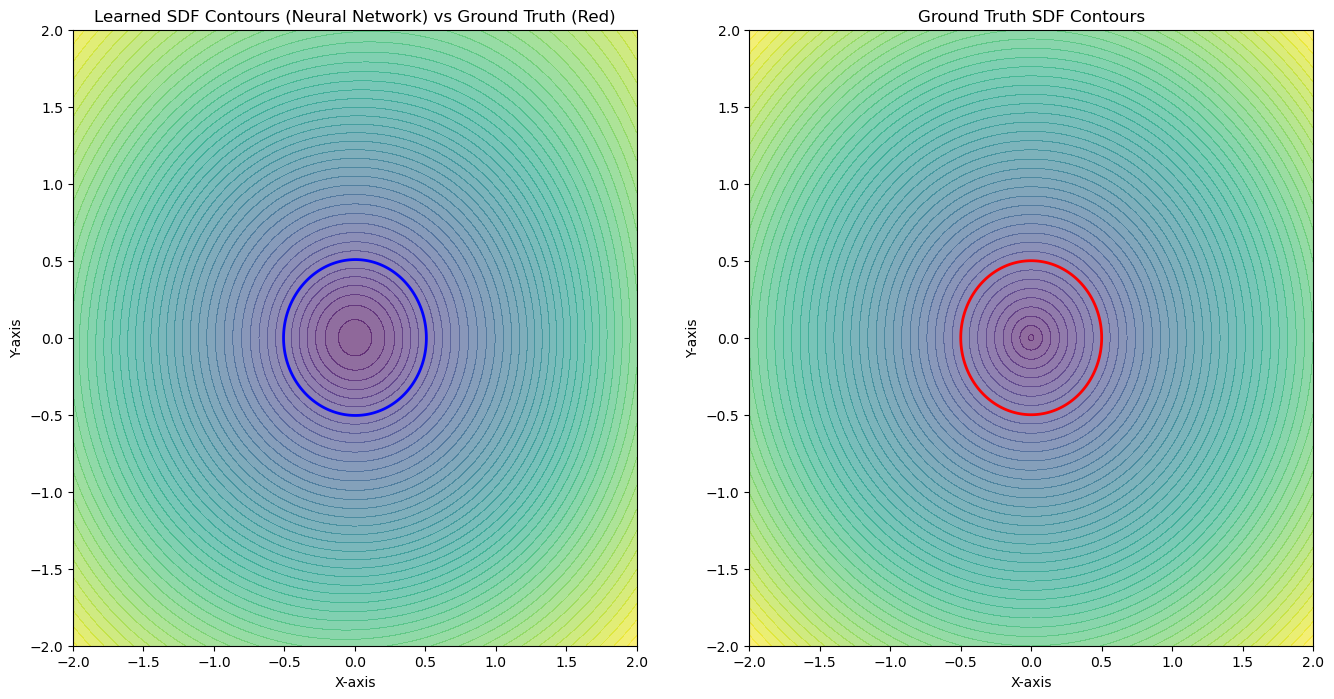

In [12]:
fig = plt.figure(figsize=(16, 8))
ax1= fig.add_subplot(121)
ax2 = fig.add_subplot(122)

x = jnp.linspace(-2.0, 2.0, 400)
y = jnp.linspace(-2.0, 2.0, 400)
X, Y = jnp.meshgrid(x, y)
points = jnp.stack([X.ravel(), Y.ravel()], axis=-1)

Z = jax.vmap(partial_neural_network)(x=points)
Z = Z.reshape(X.shape)
Z_gt = jax.vmap(lambda x: sphere_sdf(x, RADIUS))(points)
Z_gt = Z_gt.reshape(X.shape)

contourf = ax1.contourf(X, Y, Z, levels=50, cmap='viridis', alpha=0.6)
contour = ax1.contour(X, Y, Z, levels=[0.0], colors='blue', linewidths=2)
#contour_gt = ax1.contour(X, Y, Z_gt, levels=[0.0], colors='red', linewidths=2)
ax1.set_title('Learned SDF Contours (Neural Network) vs Ground Truth (Red)')
ax1.set_xlabel('X-axis')
ax1.set_ylabel('Y-axis')


contourf_gt2 = ax2.contourf(X, Y, Z_gt, levels=50, cmap='viridis', alpha=0.6)
contour_gt2 = ax2.contour(X, Y, Z_gt, levels=[0.0], colors='red', linewidths=2)
ax2.set_title('Ground Truth SDF Contours')
ax2.set_xlabel('X-axis')
ax2.set_ylabel('Y-axis')


plt.show()


In [13]:
sphere_sdf(jnp.array([0.0, 0.0]), RADIUS), neural_network(trained_params, jnp.array([0.0, 0.0]))

(Array(-0.5, dtype=float32), Array([-0.38916376], dtype=float32))

In [14]:
ab_df = jnpboundedImplicit(fn=lambda x: neural_network(trained_params, x), autobounds_max_degree=2, level_set=0.0, classification_flag='control_points')
integrator = WoSIntegrator(
    empty_sphere_fn=ab_df.empty_sphere, 
    boundary_condition_fn=boundary_condition,
    source_term_fn=lambda x: jnp.array(0.0),
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

In [11]:
def sample_sdf_rejection(key, sdf_fn: Callable, N: int, 
                         lower_bound: jnp.ndarray, 
                         upper_bound: jnp.ndarray, 
                         max_iter: int = 1000):
    """
    Sample N points uniformly inside an SDF domain using rejection sampling.
    
    Args:
        key: JAX PRNGKey.
        sdf_fn: Function taking (N, D) points and returning (N,) distances.
                Points with sdf < 0 are considered 'inside'.
        N: Number of points to sample.
        lower_bound: Min corner of the sampling domain (D,).
        upper_bound: Max corner of the sampling domain (D,).
        max_iter: Safety break to prevent infinite loops if domain is empty.
        
    Returns:
        points: (N, D) array of valid points.
        valid_mask: (N,) boolean array indicating if the slot was successfully filled.
                    (Should be all True unless max_iter was reached).
    """
    
    dim = lower_bound.shape[0]

    # Initial State
    # points: The buffer we want to fill
    # mask: Boolean array tracking which slots are successfully filled
    # key: Current RNG key
    # iter_num: Counter
    init_points = jnp.zeros((N, dim))
    init_mask = jnp.zeros((N,), dtype=bool)
    init_state = (key, init_points, init_mask, 0)

    def cond_fun(state):
        _, _, mask, i = state
        # Continue if: We have empty slots AND we haven't hit max_iter
        return jnp.logical_and(
            jnp.logical_not(jnp.all(mask)), 
            i < max_iter
        )

    def body_fun(state):
        k, current_points, current_mask, i = state
        k_sub, k_next = jax.random.split(k)
        
        # 1. Sample N candidates uniformly in the bounding box
        # Note: We generate N candidates every time. 
        # This is slightly wasteful computationally but keeps shapes static for JIT.
        candidates = jax.random.uniform(k_sub, shape=(N, dim), 
                                        minval=lower_bound, maxval=upper_bound)
        
        # 2. Check SDF
        dist = sdf_fn(candidates)
        is_inside = dist < 0.0
        
        # 3. Update Logic
        # We want to accept a candidate at index 'j' IF:
        #   - The candidate is valid (is_inside[j] is True)
        #   - AND the slot was previously empty (current_mask[j] is False)
        # Otherwise, we keep the old value (current_points[j]).
        
        should_update = is_inside & (~current_mask)
        
        # Apply updates
        new_points = jnp.where(should_update[:, None], candidates, current_points)
        new_mask = current_mask | is_inside
        
        return (k_next, new_points, new_mask, i + 1)

    # Run the loop
    final_key, final_points, final_mask, final_iters = jax.lax.while_loop(cond_fun, body_fun, init_state)
    
    return final_points, final_mask

In [16]:
# Setup
key = jax.random.PRNGKey(42)
N = 100000
bounds_min = jnp.array([-1.5, -1.5])
bounds_max = jnp.array([1.5, 1.5])

# JIT compile the sampling function for speed
sample_jit = jax.jit(sample_sdf_rejection, static_argnames=['sdf_fn', 'N', 'max_iter'])

points, mask = sample_jit(key, lambda p: neural_network(trained_params, p).squeeze(), N, bounds_min, bounds_max)

In [17]:
initial_position_batch = jnp.array([[0.0, 0.0]])
rng_key = jax.random.PRNGKey(0)
n_samples = 10
init_trust_region_size = jnp.array(0.5)
max_active_states = 1024**2
from sphereWalker.types import WalkerState

N_positions = initial_position_batch.shape[0]
N_total_samples = N_positions * n_samples
active_buffer_size = min(1, max_active_states)

### Init global output buffers
accumulated_w = jnp.zeros((N_positions,))
accumulated_nSteps = jnp.zeros((N_positions,), dtype=jnp.int32)

### Process in chunks to avoid OOM
init_task_indices = jnp.arange(active_buffer_size)
active_parent_indices = init_task_indices // n_samples
next_task_index = active_buffer_size

### Initialize active states
rng_keys_init = jax.vmap(lambda i: jr.fold_in(rng_key, i))(init_task_indices)
active_states = WalkerState(
    position=initial_position_batch[:],
    nSteps=jnp.zeros((active_buffer_size, ), dtype=jnp.int32),
    w=jnp.zeros((active_buffer_size, )),
    trust_region_size=jnp.full((active_buffer_size, ), init_trust_region_size),
    rng_key=rng_keys_init,
    done_flag=jnp.zeros((active_buffer_size, ), dtype=bool)
)

In [18]:
jnp.full((active_buffer_size, ), init_trust_region_size)

Array([0.5], dtype=float32, weak_type=True)

In [19]:
output = integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=100, init_trust_region_size=jnp.array(0.5), steps_between_refill=10, max_active_states=1024**2)

Remaining Active States: 1048575 | Next Task Index: 1048576/10000000
Process callsed so far. f1
Remaining Active States: 1048575 | Next Task Index: 1053176/10000000
Process callsed so far. f2
Remaining Active States: 1048575 | Next Task Index: 1063218/10000000
Process callsed so far. f3
Remaining Active States: 1048575 | Next Task Index: 1081064/10000000
Process callsed so far. f4
Remaining Active States: 1048575 | Next Task Index: 1106599/10000000
Process callsed so far. f5
Remaining Active States: 1048575 | Next Task Index: 1140176/10000000
Process callsed so far. f6
Remaining Active States: 1048575 | Next Task Index: 1181100/10000000
Process callsed so far. f7
Remaining Active States: 1048575 | Next Task Index: 1226803/10000000
Process callsed so far. f8
Remaining Active States: 1048575 | Next Task Index: 1277112/10000000
Process callsed so far. f9
Remaining Active States: 1048575 | Next Task Index: 1329590/10000000
Process callsed so far. f10
Remaining Active States: 1048575 | Next

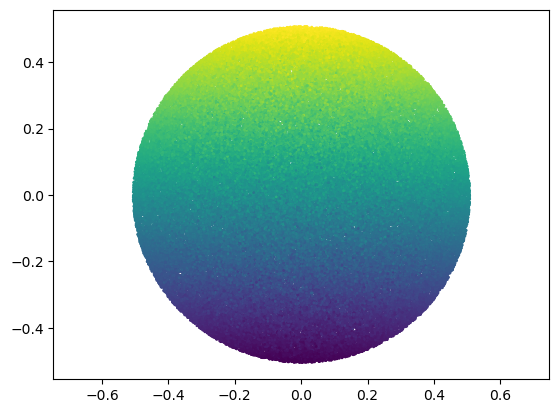

In [20]:
plt.scatter(output.position[:,0], output.position[:,1], c=output.w, s=1)
plt.axis('equal')
plt.show()

### 3d: twisted torus

In [12]:
@partial(jax.jit, static_argnames=['radius'])
def sdf_sphere_jax(x: jnp.ndarray, radius: float) -> jnp.ndarray:
    return jnp.linalg.norm(x, axis=-1) - radius


@partial(jax.jit, static_argnames=['r', 'R'])
def sdf_torus_jax(x: jnp.ndarray, r: float, R: float) -> jnp.ndarray:
    q = jnp.sqrt(jnp.pow(x[0], 2) + jnp.pow(x[2], 2)) - R
    return jnp.sqrt(jnp.pow(q, 2) + jnp.pow(x[1], 2)) - r

def twistOperation(fn: Callable, k: float) -> Callable:
    @jax.jit
    def twist(x: jnp.array):
        c = jnp.cos(k * x[1])
        s = jnp.sin(k * x[1])
        m = jnp.array([[c, 0., -s], [s, 0., c], [0., 1., 0.]])
        return fn(jnp.matmul(m, x))
    return twist

In [13]:
LEARNING_RATE = 1e-2
STEPS = 2000
RADIUS = 0.5
RADIUS_INNER = 0.2
NDIM = 3
HIDDEN_DIM = 128

params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(1))
trained_params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [14]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=NDIM,
    gt_fn=twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS), k=5.),
    n_steps=STEPS,
    bbox=(-1.5, 1.5),
    subkey=jax.random.PRNGKey(1)
)

Iteration 0, loss: 0.2735673785209656
Iteration 100, loss: 0.01504785567522049
Iteration 200, loss: 0.014834780246019363
Iteration 300, loss: 0.014833678491413593
Iteration 400, loss: 0.014661607332527637
Iteration 500, loss: 0.015092604793608189
Iteration 600, loss: 0.014517349191009998
Iteration 700, loss: 0.015142281539738178
Iteration 800, loss: 0.014976332895457745
Iteration 900, loss: 0.014865340664982796
Iteration 1000, loss: 0.013689053244888783
Iteration 1100, loss: 0.012613861821591854
Iteration 1200, loss: 0.010768584907054901
Iteration 1300, loss: 0.008284229785203934
Iteration 1400, loss: 0.0038358066231012344
Iteration 1500, loss: 0.0023975621443241835
Iteration 1600, loss: 0.0018434764351695776
Iteration 1700, loss: 0.0008818416390568018
Iteration 1800, loss: 0.0006514810957014561
Iteration 1900, loss: 0.0005402127280831337


In [15]:
points, mask = sample_sdf_rejection(jax.random.PRNGKey(0), lambda p: neural_network(trained_params, p).squeeze(), N=100000, lower_bound=jnp.array([-1.5, -1.5, -1.5]), upper_bound=jnp.array([1.5, 1.5, 1.5]))

In [25]:
jnp.all(jax.vmap(lambda p: neural_network(trained_params, p))(points) < 0.0)

Array(True, dtype=bool)

In [16]:
ab_df = jnpboundedImplicit(fn=lambda x: neural_network(trained_params, x), autobounds_max_degree=2, level_set=0.0, classification_flag='control_points')
integrator = WoSIntegrator(
    empty_sphere_fn=ab_df.empty_sphere, 
    boundary_condition_fn=boundary_condition,
    source_term_fn=lambda x: jnp.array(0.0),
    dim=3,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

In [17]:
x0 = 0.0
offset = 1.0
level_set = 0.0


x_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
y_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
z_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
X, Y, Z = jnp.meshgrid(x_vals, y_vals, z_vals)

grid_points = jnp.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=-1)
fn_vals = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, grid_points).reshape(X.shape)
#fn_vals = jax.vmap(twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS_OUTER), k=5.))(grid_points).reshape(X.shape)
fn_vals_normalized = (fn_vals - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))
fn_vals_normalized_np = fn_vals_normalized.astype(np.float64)
level_set_normalized = (level_set - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))

/system/apps/userenv/volkmann/jax_env/lib/python3.14/site-packages/jax/_src/numpy/array_methods.py:125: UserWarning: Explicitly requested dtype <class 'numpy.float64'> requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)


In [28]:
plot = k3d.plot()

iso_surf = k3d.marching_cubes(
    fn_vals_normalized_np, 
    level=level_set_normalized.astype(np.float32).item(),
    xmin=x0 - offset, xmax=x0 + offset,
    ymin=x0 - offset, ymax=x0 + offset,
    zmin=x0 - offset, zmax=x0 + offset,
    color=0x00ff00, 
    opacity=1.)
plot += iso_surf

plot.display()

Output()

In [20]:
1024**2//100

10485

In [19]:
output = integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=10, init_trust_region_size=jnp.array(0.5), steps_between_refill=10, max_active_states=1024**2//100)

Remaining Active States: 10484 | Next Task Index: 10485/1000000
Process callsed so far. f1
Remaining Active States: 10484 | Next Task Index: 12099/1000000
Process callsed so far. f2
Remaining Active States: 10484 | Next Task Index: 14794/1000000
Process callsed so far. f3
Remaining Active States: 10484 | Next Task Index: 17552/1000000
Process callsed so far. f4
Remaining Active States: 10484 | Next Task Index: 20244/1000000
Process callsed so far. f5
Remaining Active States: 10484 | Next Task Index: 23016/1000000
Process callsed so far. f6
Remaining Active States: 10484 | Next Task Index: 25795/1000000
Process callsed so far. f7
Remaining Active States: 10484 | Next Task Index: 28564/1000000
Process callsed so far. f8
Remaining Active States: 10484 | Next Task Index: 31229/1000000
Process callsed so far. f9
Remaining Active States: 10484 | Next Task Index: 33870/1000000
Process callsed so far. f10
Remaining Active States: 10484 | Next Task Index: 36605/1000000
Process callsed so far. f

In [30]:
output.w

Array([ 2.9508228 , -0.57385474, -0.80868787, ..., -0.84010375,
       -0.8740919 , -0.9166894 ], dtype=float32)

In [42]:
jnp.max(output.w), jnp.min(output.w)

(Array(nan, dtype=float32), Array(nan, dtype=float32))

In [31]:
plot = k3d.plot()

solution_points = k3d.points(output.position, point_size=0.01, color_map=matplotlib_color_maps.Coolwarm, color_range=[float(jnp.min(output.w)), float(jnp.max(output.w))], attribute=output.w)
plot += solution_points
plot.display()

Output()

In [32]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
import jax.numpy as jnp

# Assuming 'output' is your WalkerOutput object
# output.position: (N, 3)
# output.w: (N,)

def save_rotating_3d_gif(positions, values, filename='solution_rotating.gif', fps=20, duration=4):
    """
    Creates a rotating 3D scatter plot GIF using matplotlib.
    """
    fig = plt.figure(figsize=(10, 8), dpi=100)
    ax = fig.add_subplot(111, projection='3d')
    
    # 1. Create the scatter plot
    # We use the 'coolwarm' colormap as in your k3d example
    sc = ax.scatter(positions[:, 0], positions[:, 1], positions[:, 2],
                    c=values, 
                    cmap='coolwarm', 
                    s=5,    # Point size (adjust as needed)
                    alpha=0.8, # Slight transparency
                    edgecolors='none') # Faster rendering

    # 2. Add a colorbar (optional, looks nice)
    cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.05)
    cbar.set_label('Solution w')

    # 3. Remove Coordinate System (Axes, Ticks, Background)
    ax.set_axis_off()          # Turns off axis lines and labels
    ax.grid(False)             # Turns off the grid
    
    # Optional: Set a unified view limit if points are spread irregularly
    # max_range = jnp.array([positions[:,0].max()-positions[:,0].min(), 
    #                        positions[:,1].max()-positions[:,1].min(), 
    #                        positions[:,2].max()-positions[:,2].min()]).max() / 2.0
    # mid_x = (positions[:,0].max()+positions[:,0].min()) * 0.5
    # mid_y = (positions[:,1].max()+positions[:,1].min()) * 0.5
    # mid_z = (positions[:,2].max()+positions[:,2].min()) * 0.5
    # ax.set_xlim(mid_x - max_range, mid_x + max_range)
    # ax.set_ylim(mid_y - max_range, mid_y + max_range)
    # ax.set_zlim(mid_z - max_range, mid_z + max_range)

    # 4. Animation Function
    def update(frame):
        # Rotate the view: elev (elevation angle), azim (azimuth angle)
        # 360 degrees / (duration * fps) = degrees per frame
        total_frames = duration * fps
        angle = (frame / total_frames) * 360
        ax.view_init(elev=30, azim=angle)
        return sc,

    # 5. Generate and Save Animation
    total_frames = duration * fps
    ani = animation.FuncAnimation(fig, update, frames=total_frames, interval=1000/fps, blit=False)
    
    print(f"Saving {filename}...")
    ani.save(filename, writer='pillow', fps=fps)
    print("Done!")
    plt.close()

# Usage
save_rotating_3d_gif(output.position, output.w, filename='solution_rotating.gif')

Saving solution_rotating.gif...
Done!
